<a href="https://colab.research.google.com/github/PriscilaForcel/Cursos_Oficinas_Treinamentos/blob/main/WORKSHOP_AULA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de dados do Censo Demográfico 2022
## Workshop UFV | Dados censitários e aplicações para estudos urbanos

O Censo Demográfico constitui uma das principais fontes de informação para o estudo da população, dos domicílios e das condições de vida no território brasileiro. Seus dados permitem investigar desigualdades socioespaciais e apoiar análises relacionadas ao planejamento urbano e às políticas públicas.

Neste exercício, utilizaremos uma base organizada a partir dos dados do Censo Demográfico 2022, disponibilizados pelo Instituto Brasileiro de Geografia e Estatística (IBGE), com informações agregadas por setores censitários e variáveis complementares sobre o entorno dos domicílios.

A atividade será desenvolvida em duas escalas territoriais:

1. **Minas Gerais:** caracterização geral e comparação entre municípios.
2. **Viçosa:** análise intraurbana por setores censitários.

### Pergunta orientadora

Como as características demográficas e domiciliares se distribuem no território e que associações podemos identificar entre elas em diferentes escalas de análise?

### O que faremos:

- Acessar a base Parquet e consultar as variáveis necessárias;
- Explorar características demográficas e domiciliares dos municípios de Minas Gerais;
- Selecionar os setores censitários de Viçosa;
- Construir indicadores relativos;
- Associar os dados à malha de setores censitários com GeoPandas;
- Produzir mapas temáticos com Folium;
- Calcular e interpretar correlações de Pearson e Spearman.

Delimitação metodológica: esta é uma atividade de análise exploratória espacial e estatística. Não treinaremos um modelo de aprendizado de máquina nem realizaremos uma desagregação espacial efetiva. Ao final, discutiremos como essas técnicas poderiam dar continuidade à análise.

**Fonte da base:**

Forcel, Priscila. *Brazilian Population Census 2022: Integrated National Dataset of Census Tract Aggregates - Urban Environment Extension (V2).* Zenodo, versão 2.0.0.

DOI: https://doi.org/10.5281/zenodo.23821338

# 1. Preparação do ambiente de trabalho

O Google Colab é um ambiente de programação que permite executar códigos Python diretamente no navegador, sem exigir a instalação de um ambiente de desenvolvimento no computador.

Para realizar as atividades, utilizaremos bibliotecas específicas para manipulação de tabelas, consulta a arquivos de grande volume, análise geográfica e produção de gráficos e mapas.

As principais bibliotecas utilizadas serão:

- **Pandas:** organização e análise de tabelas.
- **NumPy:** operações numéricas.
- **DuckDB:** consulta a arquivos extensos, como bases Parquet.
- **GeoPandas:** leitura e manipulação de dados geográficos.
- **Folium:** elaboração de mapas interativos.
- **Matplotlib e Seaborn:** gráficos e matriz de correlação.

Nesta primeira etapa, vamos instalar e importar essas bibliotecas.

In [1]:
# 1. PREPARAÇÃO DO AMBIENTE

# Instala as bibliotecas utilizadas no workshop.
# A opção -q reduz as mensagens exibidas durante a instalação.

!pip -q install duckdb geopandas folium mapclassify pyarrow branca

# Importa as bibliotecas para manipulação e análise dos dados.

import pandas as pd
import numpy as np
import duckdb

# Bibliotecas para análise espacial e mapas.
import geopandas as gpd
import folium

# Bibliotecas para elaboração de gráficos.
import matplotlib.pyplot as plt
import seaborn as sns

# Biblioteca para análise de correlação.
from scipy.stats import pearsonr, spearmanr

# Bibliotecas auxiliares para acesso aos arquivos.
import requests
import json
import os
import zipfile

# Permite ler arquivos diretamente da memória.
from io import BytesIO

# Permite exibir tabelas no Colab.
from IPython.display import display

# Registra as versões das bibliotecas.
# Essa informação ajuda a documentar o ambiente de análise.

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("GeoPandas:", gpd.__version__)
print("DuckDB:", duckdb.__version__)

print("\nAmbiente preparado para a análise.")

Pandas: 2.2.3
NumPy: 2.4.6
GeoPandas: 1.2.0
DuckDB: 1.3.2

Ambiente preparado para a análise.


# 2. Acesso à base de dados

O arquivo principal está no formato Parquet e está hospedado no Zenodo. Primeiro consultaremos os metadados do registro para localizar automaticamente o arquivo nacional.

Por que fazer assim? O código não depende de um endereço de download digitado manualmente. Se o arquivo estiver disponível no registro, o notebook recupera seu endereço.

In [2]:
# Identificador do registro publicado no Zenodo.
ZENODO_RECORD_ID = "23821338"

# Monta o endereço da API do Zenodo.
url_api = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"

# Faz a consulta e verifica se houve erro.
resposta = requests.get(url_api, timeout=60)
resposta.raise_for_status()

# Converte a resposta da API para um dicionário Python.
registro = resposta.json()

print("Título:", registro["metadata"]["title"])
print("Versão:", registro["metadata"].get("version"))


Título: Brazilian Population Census 2022: Integrated National Dataset of Census Tract Aggregates - Urban Environment Extension (V2)
Versão: 2.0.0


## 2.1. Identificação dos arquivos disponíveis

Um registro no Zenodo pode reunir diferentes arquivos, como bases de dados, dicionários de variáveis e relatórios técnicos.

Antes de iniciar a análise, precisamos identificar quais arquivos estão disponíveis, seus formatos e tamanhos.

Essa etapa também permite localizar o arquivo Parquet que será utilizado nas consultas seguintes.

In [3]:
# 2.1. IDENTIFICAÇÃO DOS ARQUIVOS

# Recupera a relação de arquivos associados ao registro.
arquivos = registro["files"]

# Percorre os arquivos e apresenta seus nomes e tamanhos.

for arquivo in arquivos:

    nome = arquivo["key"]
    tamanho_bytes = arquivo["size"]

    # Converte o tamanho de bytes para megabytes e gigabytes.
    tamanho_mb = tamanho_bytes / (1024 ** 2)
    tamanho_gb = tamanho_bytes / (1024 ** 3)

    print("-" * 60)
    print("Arquivo:", nome)
    print(f"Tamanho: {tamanho_mb:.2f} MB")
    print(f"Tamanho: {tamanho_gb:.3f} GB")

------------------------------------------------------------
Arquivo: RELATORIO_TECNICO_UNIVERSO_2022_V2.md
Tamanho: 0.00 MB
Tamanho: 0.000 GB
------------------------------------------------------------
Arquivo: RELATORIO_VALIDACAO_UNIVERSO_2022_V2.xlsx
Tamanho: 0.01 MB
Tamanho: 0.000 GB
------------------------------------------------------------
Arquivo: UNIVERSO_2022_NACIONAL_V2.parquet
Tamanho: 276.12 MB
Tamanho: 0.270 GB
------------------------------------------------------------
Arquivo: DICIONARIO_COMPLETO_2022_V2.xlsx
Tamanho: 0.07 MB
Tamanho: 0.000 GB
------------------------------------------------------------
Arquivo: DICIONARIO_COMPLETO_2022_V2.csv
Tamanho: 0.32 MB
Tamanho: 0.000 GB


## 2.2. Seleção do arquivo Parquet

Entre os arquivos disponíveis, vamos localizar a base nacional no formato Parquet.

A seleção será feita pelo nome do arquivo. Assim, não precisamos inserir manualmente o endereço de acesso.

Essa estratégia também facilita a reprodução do notebook por outros participantes.

In [4]:
# 2.2. SELEÇÃO DO ARQUIVO PARQUET

# Localiza o arquivo Parquet da base nacional V2.

candidatos_parquet = [
    arquivo
    for arquivo in arquivos
    if arquivo["key"].endswith(".parquet")
    and "UNIVERSO_2022_NACIONAL_V2" in arquivo["key"]
]

# Verifica se o arquivo foi encontrado.

if len(candidatos_parquet) == 0:

    raise FileNotFoundError(
        "A base Parquet nacional V2 não foi encontrada. "
        "Confira os arquivos disponíveis no registro."
    )

# Armazena o arquivo selecionado.
arquivo_parquet = candidatos_parquet[0]

# Recupera o endereço de acesso ao conteúdo do arquivo.
URL_PARQUET = arquivo_parquet["links"]["self"]

print("Arquivo selecionado:", arquivo_parquet["key"])

print(
    "Tamanho:",
    round(arquivo_parquet["size"] / (1024 ** 3), 3),
    "GB"
)

print("Endereço de acesso identificado.")

# Confere se o endereço do arquivo está disponível.
print("URL identificada:", URL_PARQUET[:100], "...")

Arquivo selecionado: UNIVERSO_2022_NACIONAL_V2.parquet
Tamanho: 0.27 GB
Endereço de acesso identificado.
URL identificada: https://zenodo.org/api/records/23821338/files/UNIVERSO_2022_NACIONAL_V2.parquet/content ...


## 2.3. Conexão ao arquivo com DuckDB

O DuckDB é um sistema de gerenciamento de banco de dados que permite consultar tabelas sem precisar importar todos os dados para o Pandas.

Nesta atividade, ele será utilizado para acessar o arquivo Parquet armazenado remotamente.

Para isso, precisamos criar uma conexão em memória e habilitar o módulo `httpfs`, responsável pela leitura de arquivos disponíveis em servidores externos.

A conexão em memória não significa que toda a base será carregada no computador. As consultas seguintes selecionarão apenas os campos necessários para cada análise.

In [5]:
# 2.3. CONEXÃO COM O DUCKDB

# Cria uma conexão em memória.
con = duckdb.connect(database=":memory:")

# Instala o módulo httpfs.
# Esse módulo permite acessar arquivos armazenados remotamente.

con.execute("INSTALL httpfs")

# Carrega o módulo para a sessão atual.
con.execute("LOAD httpfs")

print("Conexão DuckDB estabelecida.")
print("Módulo httpfs carregado.")

Conexão DuckDB estabelecida.
Módulo httpfs carregado.


## 2.4. Reconhecimento da estrutura da base

Antes de selecionar as variáveis, precisamos conhecer a estrutura da tabela.

Vamos utilizar o comando `DESCRIBE` para identificar:

- a quantidade de colunas;
- os nomes dos campos;
- os tipos de dados armazenados.

Essa conferência é importante porque os códigos geográficos, como município e setor censitário, devem ser preservados como identificadores textuais.

Não devemos converter códigos geográficos em números, pois eles não representam quantidades. São códigos de identificação territorial.

In [6]:
# 2.4. ESTRUTURA DO ARQUIVO PARQUET

# Consulta a estrutura da base.
# O comando DESCRIBE apresenta os nomes e tipos das colunas.

esquema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_parquet('{URL_PARQUET}')
""").df()

# Apresenta a quantidade total de colunas.
print("Quantidade de colunas:", len(esquema))

# Exibe as primeiras 30 colunas.
display(esquema.head(30))

# Armazena os nomes das colunas disponíveis.
colunas_base = esquema["column_name"].tolist()

Quantidade de colunas: 1391


,column_name,column_type,null,key,default,extra
0,CD_SETOR,VARCHAR,YES,None,None,None
1,SITUACAO,VARCHAR,YES,None,None,None
2,CD_SIT,VARCHAR,YES,None,None,None
3,CD_TIPO,VARCHAR,YES,None,None,None
4,AREA_KM2,VARCHAR,YES,None,None,None
5,CD_REGIAO,VARCHAR,YES,None,None,None
6,NM_REGIAO,VARCHAR,YES,None,None,None
7,CD_UF,VARCHAR,YES,None,None,None
8,NM_UF,VARCHAR,YES,None,None,None
9,CD_MUN,VARCHAR,YES,None,None,None


## 2.5. Identificação dos tipos de variáveis

A estrutura da base apresenta as colunas classificadas como `VARCHAR`, ou seja, armazenadas como texto.

Isso ocorre porque o formato de origem preserva os valores como cadeias de caracteres.

Antes das operações estatísticas, será necessário converter as variáveis quantitativas para tipos numéricos.

Entretanto, os códigos geográficos, como `CD_SETOR`, `CD_MUN` e `CD_UF`, devem permanecer como texto, pois funcionam como identificadores territoriais e não como quantidades.

Essa distinção será importante nas próximas etapas de manipulação dos dados.

In [7]:
# Seleciona algumas variáveis e consulta seus tipos.
variaveis_exemplo = [
    "CD_SETOR",
    "CD_MUN",
    "v0001",
    "v0002"
]

display(
    esquema[
        esquema["column_name"].isin(variaveis_exemplo)
    ]
)

,column_name,column_type,null,key,default,extra
0,CD_SETOR,VARCHAR,YES,None,None,None
9,CD_MUN,VARCHAR,YES,None,None,None
29,v0001,VARCHAR,YES,None,None,None
30,v0002,VARCHAR,YES,None,None,None


# 3. Reconhecimento da organização territorial

A base reúne informações organizadas por setores censitários. Cada registro possui identificadores geográficos que permitem reconhecer sua localização no território brasileiro.

Esses identificadores permitem relacionar os setores censitários a diferentes níveis de agregação territorial, como municípios e Unidades da Federação.

Vamos começar identificando as Unidades da Federação (UFs) presentes na base.

Em seguida, selecionaremos Minas Gerais para iniciar a caracterização estadual e municipal.

Os códigos geográficos serão mantidos como texto, preservando sua estrutura original.

In [8]:
# 3.1. IDENTIFICAÇÃO DAS UNIDADES DA FEDERAÇÃO

# Consulta os códigos e nomes das Unidades da Federação.

ufs = con.execute(f"""
    SELECT DISTINCT
        CD_UF,
        NM_UF
    FROM read_parquet('{URL_PARQUET}')
    ORDER BY CD_UF
""").df()

# DISTINCT elimina as repetições.
# Cada Unidade da Federação aparece uma única vez.

print("Unidades da Federação identificadas:", len(ufs))

display(ufs)

Unidades da Federação identificadas: 27


,CD_UF,NM_UF
0,11,Rondônia
1,12,Acre
2,13,Amazonas
3,14,Roraima
4,15,Pará
5,16,Amapá
6,17,Tocantins
7,21,Maranhão
8,22,Piauí
9,23,Ceará


# Parte 1. Caracterização de Minas Gerais

Nesta etapa, vamos trabalhar com os municípios mineiros para compreender a distribuição territorial da população e dos domicílios.

A análise começará pela identificação dos setores censitários de cada município e avançará para a construção de indicadores demográficos e habitacionais.

# 4. Minas Gerais: caracterização territorial e demográfica

Nesta etapa, delimitaremos o recorte territorial de Minas Gerais e construiremos um panorama de seus municípios.

Primeiro, vamos identificar a quantidade de setores censitários por município. Depois, agregaremos os dados de população residente e domicílios particulares ocupados.

Essa caracterização permite reconhecer diferenças na dimensão territorial dos municípios e compreender como as informações censitárias estão distribuídas pelo estado.

Como os municípios apresentam portes populacionais muito diferentes, precisamos observar tanto os valores absolutos quanto os indicadores relativos.

Os resultados também servirão como referência para a análise posterior de Viçosa.

In [9]:
# 4.1. SELEÇÃO DE MINAS GERAIS

# Código da Unidade da Federação de Minas Gerais.
CODIGO_MG = "31"

# Consulta a quantidade de setores censitários por município.
municipios_mg = con.execute(f"""
    SELECT
        CD_UF,
        NM_UF,
        CD_MUN,
        NM_MUN,

        COUNT(DISTINCT CD_SETOR) AS TOTAL_SETORES

    FROM read_parquet('{URL_PARQUET}')

    WHERE CD_UF = '{CODIGO_MG}'

    GROUP BY
        CD_UF,
        NM_UF,
        CD_MUN,
        NM_MUN

    ORDER BY NM_MUN
""").df()

# Apresenta a quantidade de municípios identificados.
print(
    "Municípios identificados em Minas Gerais:",
    len(municipios_mg)
)

# Apresenta os primeiros registros.
display(municipios_mg.head(10))

# Calcula estatísticas sobre a quantidade de setores.
print(
    "\nTotal de setores censitários:",
    municipios_mg["TOTAL_SETORES"].sum()
)

print(
    "Média de setores por município:",
    round(municipios_mg["TOTAL_SETORES"].mean(), 2)
)

print(
    "Mediana de setores por município:",
    municipios_mg["TOTAL_SETORES"].median()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Municípios identificados em Minas Gerais: 853


,CD_UF,NM_UF,CD_MUN,NM_MUN,TOTAL_SETORES
0,31,Minas Gerais,3100104,Abadia dos Dourados,19
1,31,Minas Gerais,3100203,Abaeté,71
2,31,Minas Gerais,3100302,Abre Campo,36
3,31,Minas Gerais,3100401,Acaiaca,20
4,31,Minas Gerais,3100807,Aguanil,22
5,31,Minas Gerais,3101102,Aimorés,63
6,31,Minas Gerais,3101201,Aiuruoca,17
7,31,Minas Gerais,3101300,Alagoa,9
8,31,Minas Gerais,3101409,Albertina,8
9,31,Minas Gerais,3101607,Alfenas,221



Total de setores censitários: 51387
Média de setores por município: 60.24
Mediana de setores por município: 25.0


### 4.1.1. Municípios com maior quantidade de setores censitários

Vamos identificar os dez municípios mineiros com maior número de setores censitários registrados na base.

A distribuição da quantidade de setores entre os municípios apresenta diferenças expressivas. Enquanto metade dos municípios possui até 25 setores, alguns municípios concentram um número muito superior de unidades territoriais.

O gráfico a seguir permite visualizar essa diferença e identificar os municípios com maior quantidade de setores.

In [10]:
# Distribuição da quantidade de setores por município.

print("\nDISTRIBUIÇÃO DOS SETORES POR MUNICÍPIO")

print(
    "Mínimo:",
    municipios_mg["TOTAL_SETORES"].min()
)

print(
    "1º quartil:",
    municipios_mg["TOTAL_SETORES"].quantile(0.25)
)

print(
    "Mediana:",
    municipios_mg["TOTAL_SETORES"].median()
)

print(
    "3º quartil:",
    municipios_mg["TOTAL_SETORES"].quantile(0.75)
)

print(
    "Máximo:",
    municipios_mg["TOTAL_SETORES"].max()
)


DISTRIBUIÇÃO DOS SETORES POR MUNICÍPIO
Mínimo: 3
1º quartil: 15.0
Mediana: 25.0
3º quartil: 47.0
Máximo: 5166


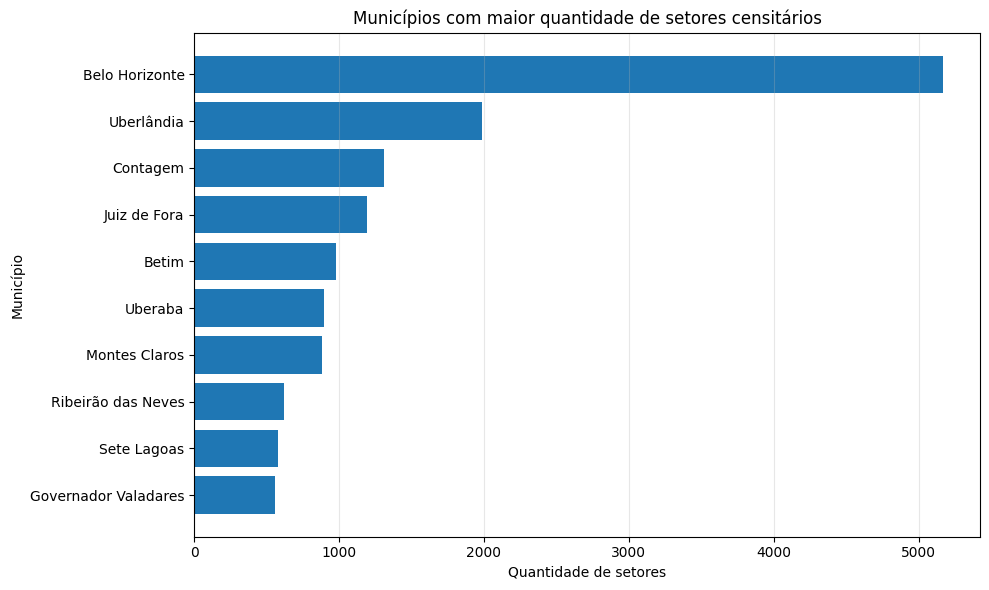

In [11]:
# Seleciona os dez municípios com maior quantidade de setores.

top_municipios = (
    municipios_mg
    .nlargest(10, "TOTAL_SETORES")
    .sort_values("TOTAL_SETORES", ascending=True)
)

# Constrói o gráfico de barras horizontais.

plt.figure(figsize=(10, 6))

plt.barh(
    top_municipios["NM_MUN"],
    top_municipios["TOTAL_SETORES"]
)

plt.title("Municípios com maior quantidade de setores censitários")
plt.xlabel("Quantidade de setores")
plt.ylabel("Município")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 4.2. População residente e domicílios particulares ocupados

Agora vamos agregar duas informações fundamentais para a caracterização demográfica e domiciliar:

- `v0001`: população residente;
- `v0007`: domicílios particulares ocupados.

A consulta será realizada por município, a partir da soma dos valores dos setores censitários que o compõem.

Como essas variáveis estão armazenadas como texto, utilizaremos `TRY_CAST` para convertê-las em números. A função retorna um valor nulo quando não consegue realizar a conversão.

Além da agregação, vamos verificar a presença de valores nulos, campos vazios e conteúdos que não puderam ser convertidos. Essa etapa permite avaliar a consistência dos dados utilizados nos cálculos.

In [12]:
caracterizacao_mg = con.execute(f"""
 SELECT
  CD_UF,
  NM_UF,
  CD_MUN,
  NM_MUN,

  COUNT(DISTINCT CD_SETOR) AS TOTAL_SETORES,

  SUM(TRY_CAST(v0001 AS BIGINT)) AS POPULACAO_RESIDENTE,
  SUM(TRY_CAST(v0007 AS BIGINT)) AS DOMICILIOS_OCUPADOS,

  COUNT(*) FILTER (
    WHERE TRY_CAST(v0001 AS BIGINT) IS NULL
      AND v0001 IS NOT NULL
      AND TRIM(v0001) <> ''
  ) AS V0001_NAO_NUMERICOS,

  COUNT(*) FILTER (
    WHERE TRY_CAST(v0007 AS BIGINT) IS NULL
      AND v0007 IS NOT NULL
      AND TRIM(v0007) <> ''
  ) AS V0007_NAO_NUMERICOS,

  COUNT(*) FILTER (
    WHERE v0001 IS NULL OR TRIM(v0001) = ''
  ) AS V0001_AUSENTES,

  COUNT(*) FILTER (
    WHERE v0007 IS NULL OR TRIM(v0007) = ''
  ) AS V0007_AUSENTES

 FROM read_parquet('{URL_PARQUET}')
 WHERE CD_UF = '{CODIGO_MG}'
 GROUP BY
  CD_UF,
  NM_UF,
  CD_MUN,
  NM_MUN
 ORDER BY NM_MUN
""").df()

# Visualizar os primeiros registros
display(caracterizacao_mg.head())

# Verificar a consistência das variáveis
print("\nVERIFICAÇÃO DE CONSISTÊNCIA DOS DADOS")
print("Total de valores não numéricos em v0001:",
      caracterizacao_mg["V0001_NAO_NUMERICOS"].sum())
print("Total de valores não numéricos em v0007:",
      caracterizacao_mg["V0007_NAO_NUMERICOS"].sum())
print("Total de valores ausentes em v0001:",
      caracterizacao_mg["V0001_AUSENTES"].sum())
print("Total de valores ausentes em v0007:",
      caracterizacao_mg["V0007_AUSENTES"].sum())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,CD_UF,NM_UF,CD_MUN,NM_MUN,TOTAL_SETORES,POPULACAO_RESIDENTE,DOMICILIOS_OCUPADOS,V0001_NAO_NUMERICOS,V0007_NAO_NUMERICOS,V0001_AUSENTES,V0007_AUSENTES
0,31,Minas Gerais,3100104,Abadia dos Dourados,19,6272.0,2580.0,0,0,0,0
1,31,Minas Gerais,3100203,Abaeté,71,22675.0,9027.0,0,0,0,0
2,31,Minas Gerais,3100302,Abre Campo,36,13927.0,4899.0,0,0,0,0
3,31,Minas Gerais,3100401,Acaiaca,20,3909.0,1507.0,0,0,0,0
4,31,Minas Gerais,3100807,Aguanil,22,4357.0,1622.0,0,0,0,0



VERIFICAÇÃO DE CONSISTÊNCIA DOS DADOS
Total de valores não numéricos em v0001: 0
Total de valores não numéricos em v0007: 0
Total de valores ausentes em v0001: 0
Total de valores ausentes em v0007: 0


### 4.2.1. Interpretação da distribuição da população e dos domicílios

A agregação dos dados dos setores censitários resultou em uma população residente de 20.539.989 pessoas e 7.538.544 domicílios particulares ocupados nos 853 municípios de Minas Gerais.

A distribuição dos valores evidencia diferenças expressivas entre os municípios. Enquanto a população média municipal é de aproximadamente 24 mil habitantes, a mediana corresponde a 8.048 habitantes. Essa diferença indica uma distribuição assimétrica, na qual os municípios mais populosos elevam o valor da média estadual.

Belo Horizonte apresenta os maiores valores de população residente e domicílios particulares ocupados, seguida por municípios como Uberlândia, Contagem e Juiz de Fora.

Esses resultados demonstram a heterogeneidade demográfica e domiciliar existente entre os municípios mineiros. Por isso, além dos valores absolutos, torna-se importante construir indicadores relativos, capazes de facilitar a comparação entre municípios de diferentes portes populacionais.

## 4.3. Construção de indicadores municipais

Os totais absolutos permitem identificar a distribuição da população e dos domicílios particulares ocupados em Minas Gerais. Entretanto, a comparação entre municípios de portes diferentes exige também o uso de indicadores relativos.

Para ampliar a análise, vamos construir três indicadores municipais:

1. **Participação na população estadual:** proporção da população residente de cada município em relação à população total de Minas Gerais.
2. **Participação nos domicílios estaduais:** proporção dos domicílios particulares ocupados de cada município em relação ao total estadual.
3. **Média de moradores por domicílio:** razão entre a população residente e o número de domicílios particulares ocupados em cada município.

Os dois primeiros indicadores permitem comparar a participação dos municípios na distribuição estadual da população e dos domicílios. O terceiro permite observar a relação entre essas duas grandezas, independentemente do porte populacional municipal.

É importante destacar que a média de moradores por domicílio não equivale ao indicador de adensamento excessivo utilizado em metodologias de mensuração do déficit habitacional. Embora ambos envolvam informações sobre população e domicílios, possuem definições e critérios de identificação distintos.

In [13]:
# Cria uma cópia da tabela original.
# Assim, preservamos os dados agregados sem alterações.

indicadores_mg = caracterizacao_mg.copy()


# PARTICIPAÇÃO NA POPULAÇÃO ESTADUAL

# Soma a população de todos os municípios.
total_populacao_mg = (
    indicadores_mg["POPULACAO_RESIDENTE"].sum()
)

# Calcula o percentual da população estadual
# residente em cada município.

indicadores_mg["PART_POP_ESTADUAL"] = (
    indicadores_mg["POPULACAO_RESIDENTE"]
    / total_populacao_mg
) * 100


# PARTICIPAÇÃO NOS DOMICÍLIOS ESTADUAIS

# Soma os domicílios particulares ocupados
# de todos os municípios.

total_domicilios_mg = (
    indicadores_mg["DOMICILIOS_OCUPADOS"].sum()
)

# Calcula o percentual dos domicílios estaduais
# localizados em cada município.

indicadores_mg["PART_DOM_ESTADUAL"] = (
    indicadores_mg["DOMICILIOS_OCUPADOS"]
    / total_domicilios_mg
) * 100


# MÉDIA DE MORADORES POR DOMICÍLIO

# Divide a população residente pela quantidade
# de domicílios particulares ocupados.
#
# O replace(0, np.nan) evita divisões por zero.

indicadores_mg["MORADORES_POR_DOMICILIO"] = (
    indicadores_mg["POPULACAO_RESIDENTE"]
    / indicadores_mg["DOMICILIOS_OCUPADOS"].replace(0, np.nan)
)


# VERIFICAÇÃO DOS INDICADORES PERCENTUAIS

print(
    "Soma da participação populacional:",
    round(indicadores_mg["PART_POP_ESTADUAL"].sum(), 2),
    "%"
)

print(
    "Soma da participação dos domicílios:",
    round(indicadores_mg["PART_DOM_ESTADUAL"].sum(), 2),
    "%"
)


# ORGANIZAÇÃO DOS RESULTADOS

# Ordena os municípios pela população residente,
# do maior para o menor.

indicadores_mg = indicadores_mg.sort_values(
    "POPULACAO_RESIDENTE",
    ascending=False
)


# Apresenta os dez municípios mais populosos
# e seus respectivos indicadores.

display(
    indicadores_mg[
        [
            "NM_MUN",
            "POPULACAO_RESIDENTE",
            "DOMICILIOS_OCUPADOS",
            "PART_POP_ESTADUAL",
            "PART_DOM_ESTADUAL",
            "MORADORES_POR_DOMICILIO"
        ]
    ].head(10).round(2)
)


Soma da participação populacional: 100.0 %
Soma da participação dos domicílios: 100.0 %


,NM_MUN,POPULACAO_RESIDENTE,DOMICILIOS_OCUPADOS,PART_POP_ESTADUAL,PART_DOM_ESTADUAL,MORADORES_POR_DOMICILIO
61,Belo Horizonte,2315560.0,890126.0,11.27,11.81,2.60
819,Uberlândia,713224.0,268162.0,3.47,3.56,2.66
199,Contagem,621863.0,228867.0,3.03,3.04,2.72
414,Juiz de Fora,540756.0,211058.0,2.63,2.80,2.56
495,Montes Claros,414240.0,144847.0,2.02,1.92,2.86
67,Betim,411846.0,146913.0,2.01,1.95,2.80
818,Uberaba,337836.0,127422.0,1.64,1.69,2.65
633,Ribeirão das Neves,329794.0,113168.0,1.61,1.50,2.91
310,Governador Valadares,257171.0,97817.0,1.25,1.30,2.63
243,Divinópolis,231091.0,87127.0,1.13,1.16,2.65


### 4.3.1. Interpretação dos indicadores municipais

Os indicadores relativos permitem observar a participação de cada município na distribuição estadual da população e dos domicílios particulares ocupados. A soma das participações municipais corresponde a 100% nos dois indicadores, confirmando a distribuição dos totais estaduais entre os municípios analisados.

Belo Horizonte apresenta a maior participação entre os municípios analisados, concentrando 11,27% da população e 11,81% dos domicílios particulares ocupados de Minas Gerais. Os resultados também evidenciam diferenças na média de moradores por domicílio. Entre os dez municípios mais populosos, os valores variam de 2,56, em Juiz de Fora, a 2,91, em Ribeirão das Neves.

Essas diferenças demonstram que municípios com portes populacionais distintos também apresentam relações diferentes entre população e domicílios. Entretanto, a média de moradores por domicílio constitui um indicador geral e não permite identificar diretamente situações de adensamento excessivo ou déficit habitacional.

A construção desses indicadores encerra a caracterização municipal de Minas Gerais e prepara a análise para uma escala territorial mais detalhada, na qual será possível investigar as diferenças existentes entre setores censitários.

In [16]:
# DIAGNÓSTICO DE VALORES AUSENTES

# Garante a definição das variáveis válidas
variaveis_validas = [
    "DOM1_V00001",
    "DOM1_V00002",
    "DOM1_V00005",
    "DOM1_V00006"
]

# Consulta os dados caso ainda não tenham sido gerados no kernel
try:
    dados_setores_mg
except NameError:
    dados_setores_mg = con.execute(f"""
        SELECT
            CD_MUN,
            NM_MUN,
            CD_SETOR,
            TRY_CAST(DOM1_V00001 AS DOUBLE) AS DOM1_V00001,
            TRY_CAST(DOM1_V00002 AS DOUBLE) AS DOM1_V00002,
            TRY_CAST(DOM1_V00005 AS DOUBLE) AS DOM1_V00005,
            TRY_CAST(DOM1_V00006 AS DOUBLE) AS DOM1_V00006
        FROM read_parquet('{URL_PARQUET}')
        WHERE CD_UF = '{CODIGO_MG}'
    """).df()

print("Total de setores na base:", len(dados_setores_mg))

print("\nValores ausentes por variável:")
display(
    dados_setores_mg[variaveis_validas]
    .isna()
    .sum()
    .to_frame("VALORES_AUSENTES")
)

# Identifica setores com informações completas
# nas quatro variáveis.

setores_completos = dados_setores_mg[
    variaveis_validas
].notna().all(axis=1)

print(
    "\nSetores com informações completas:",
    setores_completos.sum()
)

print(
    "Setores com pelo menos um valor ausente:",
    (~setores_completos).sum()
)

print(
    "Cobertura das informações:",
    round(setores_completos.mean() * 100, 2),
    "%"
)

Total de setores na base: 47358

Valores ausentes por variável:


,VALORES_AUSENTES
DOM1_V00001,0
DOM1_V00002,0
DOM1_V00005,0
DOM1_V00006,0



Setores com informações completas: 47358
Setores com pelo menos um valor ausente: 0
Cobertura das informações: 100.0 %


In [17]:
# Consulta às quatro variáveis domiciliares
# para todos os setores de Minas Gerais.

dados_setores_mg = con.execute(f"""
    SELECT
        CD_MUN,
        NM_MUN,
        CD_SETOR,

        TRY_CAST(DOM1_V00001 AS DOUBLE) AS DOM1_V00001,
        TRY_CAST(DOM1_V00002 AS DOUBLE) AS DOM1_V00002,
        TRY_CAST(DOM1_V00005 AS DOUBLE) AS DOM1_V00005,
        TRY_CAST(DOM1_V00006 AS DOUBLE) AS DOM1_V00006

    FROM read_parquet('{URL_PARQUET}')

    WHERE CD_UF = '{CODIGO_MG}'
""").df()


# Mantém setores com informações completas.
variaveis_validas = [
    "DOM1_V00001",
    "DOM1_V00002",
    "DOM1_V00005",
    "DOM1_V00006"
]
# Para construir os indicadores, mantemos apenas
# setores com informações disponíveis nas quatro variáveis.
#
# A cobertura da análise foi verificada na célula anterior.

dados_setores_mg = dados_setores_mg.dropna(
    subset=variaveis_validas
).copy()
dados_setores_mg = dados_setores_mg.dropna(
    subset=variaveis_validas
).copy()


# Calcula os totais por setor.
dados_setores_mg["DOMICILIOS_CONSIDERADOS"] = (
    dados_setores_mg["DOM1_V00001"]
    + dados_setores_mg["DOM1_V00002"]
)

dados_setores_mg["POPULACAO_CONSIDERADA"] = (
    dados_setores_mg["DOM1_V00005"]
    + dados_setores_mg["DOM1_V00006"]
)


# Agrega os dados por município.
indicadores_hab_mg = (
    dados_setores_mg
    .groupby(["CD_MUN", "NM_MUN"])
    .agg(
        DOMICILIOS=(
            "DOMICILIOS_CONSIDERADOS", "sum"
        ),
        POPULACAO=(
            "POPULACAO_CONSIDERADA", "sum"
        ),
        DOM_IMPROVISADOS=(
            "DOM1_V00002", "sum"
        ),
        TOTAL_SETORES=(
            "CD_SETOR", "nunique"
        )
    )
    .reset_index()
)


# Constrói os indicadores municipais.
indicadores_hab_mg["PCT_IMPROVISADOS"] = (
    indicadores_hab_mg["DOM_IMPROVISADOS"]
    / indicadores_hab_mg["DOMICILIOS"].replace(0, np.nan)
) * 100

indicadores_hab_mg["MEDIA_MORADORES"] = (
    indicadores_hab_mg["POPULACAO"]
    / indicadores_hab_mg["DOMICILIOS"].replace(0, np.nan)
)


# Apresenta os resultados.
display(
    indicadores_hab_mg.sort_values(
        "PCT_IMPROVISADOS",
        ascending=False
    ).head(10).round(2)
)

,CD_MUN,NM_MUN,DOMICILIOS,POPULACAO,DOM_IMPROVISADOS,TOTAL_SETORES,PCT_IMPROVISADOS,MEDIA_MORADORES
272,3124401,Espírito Santo do Dourado,2201.0,6327.0,159.0,14,7.22,2.87
737,3162922,São Joaquim de Bicas,7475.0,21666.0,225.0,40,3.01,2.90
396,3135076,Jampruca,955.0,2554.0,14.0,10,1.47,2.67
216,3119807,Córrego Danta,1183.0,2878.0,12.0,12,1.01,2.43
422,3136959,Juvenília,1662.0,5208.0,16.0,16,0.96,3.13
593,3150703,Pirajuba,2062.0,5537.0,19.0,15,0.92,2.69
644,3155405,Rio Novo,2961.0,8044.0,25.0,22,0.84,2.72
4,3100500,Açucena,3006.0,8028.0,24.0,34,0.80,2.67
731,3162575,São João do Manteninha,1641.0,4112.0,12.0,15,0.73,2.51
472,3140852,Matias Cardoso,2037.0,6198.0,12.0,25,0.59,3.04


### 4.4. Análise das características domiciliares em Minas Gerais

Nesta etapa, vamos ampliar a caracterização municipal com informações domiciliares disponíveis na base integrada do Censo Demográfico 2022.

Para isso, selecionaremos quatro variáveis referentes aos domicílios e à população residente:

- `DOM1_V00001`;
- `DOM1_V00002`;
- `DOM1_V00005`;
- `DOM1_V00006`.

A partir dessas variáveis, construiremos dois indicadores municipais:

- Percentual de domicílios improvisados;
- Média de moradores por domicílio.

Antes de calcular os indicadores, vamos verificar a disponibilidade das informações e a cobertura dos setores censitários na consulta. Essa etapa é importante para avaliar se a análise contempla o mesmo conjunto de unidades territoriais utilizado na caracterização municipal anterior.

In [18]:
# Consulta às quatro variáveis domiciliares
# para todos os setores de Minas Gerais.

dados_setores_mg = con.execute(f"""
    SELECT
        CD_MUN,
        NM_MUN,
        CD_SETOR,

        TRY_CAST(DOM1_V00001 AS DOUBLE) AS DOM1_V00001,
        TRY_CAST(DOM1_V00002 AS DOUBLE) AS DOM1_V00002,
        TRY_CAST(DOM1_V00005 AS DOUBLE) AS DOM1_V00005,
        TRY_CAST(DOM1_V00006 AS DOUBLE) AS DOM1_V00006

    FROM read_parquet('{URL_PARQUET}')

    WHERE CD_UF = '{CODIGO_MG}'
""").df()


# Lista das variáveis utilizadas na análise.

variaveis_validas = [
    "DOM1_V00001",
    "DOM1_V00002",
    "DOM1_V00005",
    "DOM1_V00006"
]


print("Total de registros da consulta:", len(dados_setores_mg))

print(
    "Total de setores distintos:",
    dados_setores_mg["CD_SETOR"].nunique()
)

print(
    "Total de municípios:",
    dados_setores_mg["CD_MUN"].nunique()
)

Total de registros da consulta: 51387
Total de setores distintos: 51387
Total de municípios: 853


In [19]:
# DIAGNÓSTICO DE VALORES AUSENTES

print("Total de setores na consulta:", len(dados_setores_mg))

print("\nValores ausentes por variável:")

display(
    dados_setores_mg[variaveis_validas]
    .isna()
    .sum()
    .to_frame("VALORES_AUSENTES")
)


# Identifica setores com informações completas
# nas quatro variáveis.

setores_completos = dados_setores_mg[
    variaveis_validas
].notna().all(axis=1)


print(
    "\nSetores com informações completas:",
    setores_completos.sum()
)

print(
    "Setores com pelo menos um valor ausente:",
    (~setores_completos).sum()
)

print(
    "Cobertura das informações:",
    round(setores_completos.mean() * 100, 2),
    "%"
)

Total de setores na consulta: 51387

Valores ausentes por variável:


,VALORES_AUSENTES
DOM1_V00001,1092
DOM1_V00002,4029
DOM1_V00005,1092
DOM1_V00006,3123



Setores com informações completas: 47358
Setores com pelo menos um valor ausente: 4029
Cobertura das informações: 92.16 %


In [20]:
# COBERTURA DOS SETORES POR MUNICÍPIO


# Total de setores identificados na consulta municipal da seção 4.1.

setores_base_mg = (
    municipios_mg[
        ["CD_MUN", "NM_MUN", "TOTAL_SETORES"]
    ]
    .rename(
        columns={"TOTAL_SETORES": "SETORES_BASE"}
    )
)


# Total de setores presentes na consulta domiciliar.

setores_consulta_mg = (
    dados_setores_mg
    .groupby(["CD_MUN", "NM_MUN"])
    .agg(
        SETORES_CONSULTA=("CD_SETOR", "nunique")
    )
    .reset_index()
)


# Total de setores com informações completas.

setores_validos_mg = (
    dados_setores_mg.loc[setores_completos]
    .groupby(["CD_MUN", "NM_MUN"])
    .agg(
        SETORES_VALIDOS=("CD_SETOR", "nunique")
    )
    .reset_index()
)


# Reúne as três informações em uma única tabela.

cobertura_mg = (
    setores_base_mg
    .merge(
        setores_consulta_mg,
        on=["CD_MUN", "NM_MUN"],
        how="left"
    )
    .merge(
        setores_validos_mg,
        on=["CD_MUN", "NM_MUN"],
        how="left"
    )
)


# Substitui valores ausentes por zero nas contagens.

colunas_setores = [
    "SETORES_CONSULTA",
    "SETORES_VALIDOS"
]

cobertura_mg[colunas_setores] = (
    cobertura_mg[colunas_setores]
    .fillna(0)
)


# Calcula a cobertura da consulta domiciliar
# em relação aos setores identificados na seção 4.1.

cobertura_mg["PCT_COBERTURA_CONSULTA"] = (
    cobertura_mg["SETORES_CONSULTA"]
    / cobertura_mg["SETORES_BASE"]
) * 100


# Calcula a cobertura dos setores com informações completas.

cobertura_mg["PCT_COBERTURA_VALIDA"] = (
    cobertura_mg["SETORES_VALIDOS"]
    / cobertura_mg["SETORES_BASE"]
) * 100


# Apresenta os resultados gerais.

print("TOTAL DE SETORES NA BASE MUNICIPAL:",
      cobertura_mg["SETORES_BASE"].sum())

print("TOTAL DE SETORES NA CONSULTA DOMICILIAR:",
      cobertura_mg["SETORES_CONSULTA"].sum())

print("TOTAL DE SETORES COM INFORMAÇÕES COMPLETAS:",
      cobertura_mg["SETORES_VALIDOS"].sum())


print(
    "\nCobertura geral da consulta:",
    round(
        cobertura_mg["SETORES_CONSULTA"].sum()
        / cobertura_mg["SETORES_BASE"].sum() * 100,
        2
    ),
    "%"
)


print(
    "Cobertura geral dos setores válidos:",
    round(
        cobertura_mg["SETORES_VALIDOS"].sum()
        / cobertura_mg["SETORES_BASE"].sum() * 100,
        2
    ),
    "%"
)


# Apresenta os municípios com menor cobertura.

print("\nMUNICÍPIOS COM MENOR COBERTURA:")

display(
    cobertura_mg
    .sort_values("PCT_COBERTURA_VALIDA")
    .head(10)
    .round(2)
)

TOTAL DE SETORES NA BASE MUNICIPAL: 51387
TOTAL DE SETORES NA CONSULTA DOMICILIAR: 51387
TOTAL DE SETORES COM INFORMAÇÕES COMPLETAS: 47358

Cobertura geral da consulta: 100.0 %
Cobertura geral dos setores válidos: 92.16 %

MUNICÍPIOS COM MENOR COBERTURA:


,CD_MUN,NM_MUN,SETORES_BASE,SETORES_CONSULTA,SETORES_VALIDOS,PCT_COBERTURA_CONSULTA,PCT_COBERTURA_VALIDA
733,3160801,São Bento Abade,8,8,4,100.0,50.00
15,3102050,Alto Caparaó,14,14,7,100.0,50.00
198,3118502,Consolação,7,7,4,100.0,57.14
791,3165206,São Tomé das Letras,22,22,13,100.0,59.09
465,3171501,Mathias Lobato,8,8,5,100.0,62.50
777,3164100,São Pedro do Suaçuí,14,14,9,100.0,64.29
748,3125507,São Gonçalo do Rio Preto,6,6,4,100.0,66.67
271,3124609,Estrela Dalva,9,9,6,100.0,66.67
718,3166600,Serra da Saudade,3,3,2,100.0,66.67
309,3127602,Gouveia,22,22,15,100.0,68.18


Após o diagnóstico, identificamos que 47.358 dos 51.387 setores consultados apresentam informações disponíveis nas quatro variáveis selecionadas, o que corresponde a uma cobertura de 92,16%.

Para construir os indicadores, vamos manter apenas os setores com informações completas nas quatro variáveis. Esse procedimento permite utilizar um conjunto comum de informações no cálculo dos indicadores, mas implica a exclusão de 4.029 setores.

Essa redução exige atenção na interpretação dos resultados, pois a cobertura varia entre os municípios. Assim, os indicadores calculados representam os setores com informações completas e não necessariamente a totalidade das unidades territoriais de cada município.

In [21]:
# Mantém setores com informações completas
# nas quatro variáveis.

dados_setores_mg = dados_setores_mg.dropna(
    subset=variaveis_validas
).copy()


print(
    "Total de setores após o tratamento:",
    dados_setores_mg["CD_SETOR"].nunique()
)

Total de setores após o tratamento: 47358


Com os dados organizados, vamos construir os indicadores municipais.

Primeiro, somaremos as variáveis selecionadas para obter os totais de domicílios e população considerados na análise. Em seguida, calcularemos o percentual de domicílios improvisados em relação ao total de domicílios considerados e a média de moradores por domicílio.

Esses indicadores permitem explorar diferenças nas características domiciliares entre os municípios mineiros.

In [22]:
# Calcula os totais por setor.

dados_setores_mg["DOMICILIOS_CONSIDERADOS"] = (
    dados_setores_mg["DOM1_V00001"]
    + dados_setores_mg["DOM1_V00002"]
)

dados_setores_mg["POPULACAO_CONSIDERADA"] = (
    dados_setores_mg["DOM1_V00005"]
    + dados_setores_mg["DOM1_V00006"]
)


# Agrega os dados por município.

indicadores_hab_mg = (
    dados_setores_mg
    .groupby(["CD_MUN", "NM_MUN"])
    .agg(
        DOMICILIOS=(
            "DOMICILIOS_CONSIDERADOS", "sum"
        ),
        POPULACAO=(
            "POPULACAO_CONSIDERADA", "sum"
        ),
        DOM_IMPROVISADOS=(
            "DOM1_V00002", "sum"
        ),
        TOTAL_SETORES=(
            "CD_SETOR", "nunique"
        )
    )
    .reset_index()
)


# Constrói os indicadores municipais.

indicadores_hab_mg["PCT_IMPROVISADOS"] = (
    indicadores_hab_mg["DOM_IMPROVISADOS"]
    / indicadores_hab_mg["DOMICILIOS"].replace(0, np.nan)
) * 100


indicadores_hab_mg["MEDIA_MORADORES"] = (
    indicadores_hab_mg["POPULACAO"]
    / indicadores_hab_mg["DOMICILIOS"].replace(0, np.nan)
)


# Apresenta os dez municípios com maior percentual
# de domicílios improvisados.

display(
    indicadores_hab_mg.sort_values(
        "PCT_IMPROVISADOS",
        ascending=False
    ).head(10).round(2)
)

,CD_MUN,NM_MUN,DOMICILIOS,POPULACAO,DOM_IMPROVISADOS,TOTAL_SETORES,PCT_IMPROVISADOS,MEDIA_MORADORES
272,3124401,Espírito Santo do Dourado,2201.0,6327.0,159.0,14,7.22,2.87
737,3162922,São Joaquim de Bicas,7475.0,21666.0,225.0,40,3.01,2.90
396,3135076,Jampruca,955.0,2554.0,14.0,10,1.47,2.67
216,3119807,Córrego Danta,1183.0,2878.0,12.0,12,1.01,2.43
422,3136959,Juvenília,1662.0,5208.0,16.0,16,0.96,3.13
593,3150703,Pirajuba,2062.0,5537.0,19.0,15,0.92,2.69
644,3155405,Rio Novo,2961.0,8044.0,25.0,22,0.84,2.72
4,3100500,Açucena,3006.0,8028.0,24.0,34,0.80,2.67
731,3162575,São João do Manteninha,1641.0,4112.0,12.0,15,0.73,2.51
472,3140852,Matias Cardoso,2037.0,6198.0,12.0,25,0.59,3.04


Os resultados permitem identificar diferenças entre os municípios mineiros quanto à participação dos domicílios improvisados e à média de moradores por domicílio.

A ordenação pelo percentual de domicílios improvisados destaca municípios que apresentam maior participação dessa categoria no conjunto de domicílios considerados.

Entretanto, a interpretação dos percentuais também exige atenção aos valores absolutos e ao tamanho da base de cada município. Municípios com poucos domicílios podem apresentar percentuais elevados mesmo quando o número absoluto de domicílios improvisados é relativamente baixo.

A média de moradores por domicílio, por sua vez, permite observar a relação entre população e quantidade de domicílios, mas não identifica diretamente situações de adensamento excessivo ou déficit habitacional.

#### 4.4.1. Correlação entre os indicadores municipais

Com os indicadores calculados, vamos investigar a associação entre o percentual de domicílios improvisados e a média de moradores por domicílio nos municípios de Minas Gerais.

Utilizaremos dois coeficientes:

- **Pearson (r):** identifica a intensidade e a direção da associação linear.
- **Spearman (ρ):** identifica a intensidade e a direção da associação monotônica, a partir da ordenação dos valores.

A comparação entre os dois coeficientes permite observar se a associação entre os indicadores apresenta comportamento linear ou monotônico.

Os resultados possuem caráter exploratório. Os coeficientes de correlação não permitem estabelecer relações de causalidade.

In [23]:
from scipy.stats import pearsonr, spearmanr


# Seleciona os indicadores e remove valores ausentes.

correlacao_mg = indicadores_hab_mg[
    ["PCT_IMPROVISADOS", "MEDIA_MORADORES"]
].replace([np.inf, -np.inf], np.nan).dropna()


# Calcula os coeficientes.

r_pearson, p_pearson = pearsonr(
    correlacao_mg["PCT_IMPROVISADOS"],
    correlacao_mg["MEDIA_MORADORES"]
)


r_spearman, p_spearman = spearmanr(
    correlacao_mg["PCT_IMPROVISADOS"],
    correlacao_mg["MEDIA_MORADORES"]
)


print("Municípios analisados:", len(correlacao_mg))


print("\nCORRELAÇÃO DE PEARSON")
print("Coeficiente:", round(r_pearson, 4))
print("Valor-p:", round(p_pearson, 4))


print("\nCORRELAÇÃO DE SPEARMAN")
print("Coeficiente:", round(r_spearman, 4))
print("Valor-p:", round(p_spearman, 4))

Municípios analisados: 853

CORRELAÇÃO DE PEARSON
Coeficiente: 0.0343
Valor-p: 0.3164

CORRELAÇÃO DE SPEARMAN
Coeficiente: 0.0059
Valor-p: 0.8629


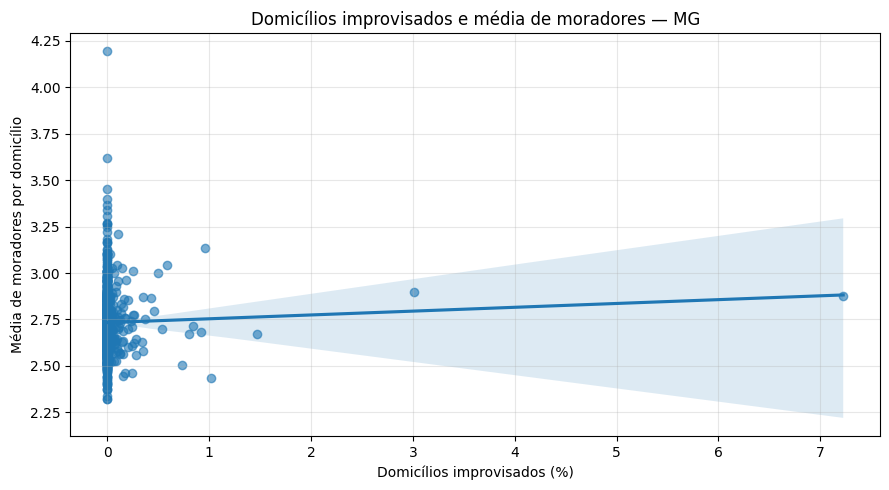

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(9, 5))


sns.regplot(
    data=correlacao_mg,
    x="PCT_IMPROVISADOS",
    y="MEDIA_MORADORES",
    scatter_kws={"alpha": 0.6}
)


plt.title(
    "Domicílios improvisados e média de moradores — MG"
)

plt.xlabel("Domicílios improvisados (%)")
plt.ylabel("Média de moradores por domicílio")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Os coeficientes obtidos apresentam valores próximos de zero, indicando uma associação muito fraca entre o percentual de domicílios improvisados e a média de moradores por domicílio nos municípios analisados.

Os valores-p foram superiores a 0,05 para os dois coeficientes, não permitindo identificar evidência estatística suficiente de associação entre os indicadores.

É importante considerar que os indicadores foram construídos a partir de setores com informações completas nas quatro variáveis selecionadas. Como a cobertura varia entre os municípios, os resultados devem ser interpretados com cautela.

Além disso, a correlação foi calculada com dados agregados por município. Portanto, os resultados descrevem associações observadas nessa escala territorial e não devem ser transferidos diretamente para domicílios ou setores censitários.

In [26]:
# PADRÃO DE VALORES AUSENTES

# Recupera os dados originais do DuckDB antes do descarte (dropna)
dados_setores_mg_original = con.execute(f"""
    SELECT
        CD_MUN,
        NM_MUN,
        CD_SETOR,
        TRY_CAST(DOM1_V00001 AS DOUBLE) AS DOM1_V00001,
        TRY_CAST(DOM1_V00002 AS DOUBLE) AS DOM1_V00002,
        TRY_CAST(DOM1_V00005 AS DOUBLE) AS DOM1_V00005,
        TRY_CAST(DOM1_V00006 AS DOUBLE) AS DOM1_V00006
    FROM read_parquet('{URL_PARQUET}')
    WHERE CD_UF = '{CODIGO_MG}'
""").df()

print("Combinações de valores ausentes nas quatro variáveis:")

display(
    dados_setores_mg_original[
        variaveis_validas
    ].isna().value_counts().reset_index(name="QUANTIDADE")
)

Combinações de valores ausentes nas quatro variáveis:


,DOM1_V00001,DOM1_V00002,DOM1_V00005,DOM1_V00006,QUANTIDADE
0,False,False,False,False,47358
1,False,True,False,True,2031
2,True,True,True,True,1092
3,False,True,False,False,906


# **VIÇOSA: ANÁLISE INTRAURBANA POR SETORES CENSITÁRIOS**

Até aqui, trabalhamos com os dados agregados por município, observando a distribuição da população e dos domicílios em Minas Gerais.

Nesta etapa, vamos aproximar a escala de análise e trabalhar com o município de Viçosa, utilizando os setores censitários como unidades territoriais.

O objetivo é explorar a distribuição das características domiciliares entre os setores, construindo indicadores que permitam identificar possíveis diferenças intraurbanas.

Para isso, vamos selecionar as informações de Viçosa na base censitária, calcular indicadores relativos às condições domiciliares, integrar os dados à malha de setores censitários e produzir mapas temáticos.

Essa mudança de escala permite observar desigualdades que podem não aparecer quando os dados são analisados apenas no nível municipal.

# **5.1. Seleção dos setores censitários de Viçosa**

Nesta etapa, vamos selecionar os registros correspondentes ao município de Viçosa.

Utilizaremos o código geográfico municipal 3171303, mantendo os identificadores territoriais como texto.

Para a análise, vamos trabalhar inicialmente com quatro variáveis:
Variável	Informação
DOM1_V00001	Domicílios particulares permanentes ocupados
DOM1_V00002	Domicílios particulares improvisados ocupados
DOM1_V00005	Moradores em domicílios particulares permanentes ocupados
DOM1_V00006	Moradores em domicílios particulares improvisados ocupados

Essas variáveis permitem construir indicadores exploratórios relacionados à presença de domicílios improvisados e à relação entre moradores e domicílios.

In [27]:
# Código municipal de Viçosa.
CODIGO_VICOSA = "3171303"


# Seleciona os setores censitários de Viçosa
# e as quatro variáveis domiciliares escolhidas.

dados_vicosa = con.execute(f"""
    SELECT
        CD_UF,
        CD_MUN,
        NM_MUN,
        CD_SETOR,

        TRY_CAST(DOM1_V00001 AS BIGINT) AS DOM1_V00001,
        TRY_CAST(DOM1_V00002 AS BIGINT) AS DOM1_V00002,
        TRY_CAST(DOM1_V00005 AS BIGINT) AS DOM1_V00005,
        TRY_CAST(DOM1_V00006 AS BIGINT) AS DOM1_V00006

    FROM read_parquet('{URL_PARQUET}')

    WHERE CD_MUN = '{CODIGO_VICOSA}'

    ORDER BY CD_SETOR
""").df()


# Apresenta a quantidade de setores identificados.

print("Município:", dados_vicosa["NM_MUN"].iloc[0])
print("Setores censitários identificados:", len(dados_vicosa))


# Visualiza os primeiros registros.

display(dados_vicosa.head())


Município: Viçosa
Setores censitários identificados: 178


,CD_UF,CD_MUN,NM_MUN,CD_SETOR,DOM1_V00001,DOM1_V00002,DOM1_V00005,DOM1_V00006
0,31,3171303,Viçosa,317130305000007,201,0,526,0
1,31,3171303,Viçosa,317130305000008,185,0,520,0
2,31,3171303,Viçosa,317130305000011,196,0,519,0
3,31,3171303,Viçosa,317130305000014,179,0,449,0
4,31,3171303,Viçosa,317130305000015,247,0,654,0


### 5.2. Construção de indicadores domiciliares por setor

Com os dados de Viçosa selecionados, vamos construir dois indicadores exploratórios:

1. **Percentual de domicílios improvisados:** participação dos domicílios particulares improvisados ocupados no total de domicílios considerados.
2. **Média de moradores por domicílio:** relação entre o total de moradores e o total de domicílios considerados.

Antes dos cálculos, precisamos observar os valores ausentes. Como alguns dados podem estar protegidos por sigilo estatístico, não devemos substituir automaticamente os valores ausentes por zero.

Assim, os indicadores serão calculados apenas quando as informações necessárias estiverem disponíveis.

In [28]:
# Cria uma cópia dos dados selecionados.
dados_vicosa = dados_vicosa.copy()

# Identifica os registros com todas as variáveis disponíveis.
variaveis_validas = [
    "DOM1_V00001",
    "DOM1_V00002",
    "DOM1_V00005",
    "DOM1_V00006"
]

dados_vicosa["DADOS_VALIDOS"] = (
    dados_vicosa[variaveis_validas]
    .notna()
    .all(axis=1)
)

print("Setores identificados:", len(dados_vicosa))
print(
    "Setores com dados completos:",
    dados_vicosa["DADOS_VALIDOS"].sum()
)
print(
    "Setores com alguma informação ausente:",
    (~dados_vicosa["DADOS_VALIDOS"]).sum()
)

# Calcula os indicadores somente para registros completos.
dados_vicosa["DOMICILIOS_CONSIDERADOS"] = np.where(
    dados_vicosa["DADOS_VALIDOS"],
    dados_vicosa["DOM1_V00001"] + dados_vicosa["DOM1_V00002"],
    np.nan
)

dados_vicosa["POPULACAO_CONSIDERADA"] = np.where(
    dados_vicosa["DADOS_VALIDOS"],
    dados_vicosa["DOM1_V00005"] + dados_vicosa["DOM1_V00006"],
    np.nan
)

# Percentual de domicílios improvisados.
dados_vicosa["PCT_IMPROVISADOS"] = (
    dados_vicosa["DOM1_V00002"]
    / dados_vicosa["DOMICILIOS_CONSIDERADOS"].replace(0, np.nan)
) * 100

# Média de moradores por domicílio.
dados_vicosa["MEDIA_MORADORES"] = (
    dados_vicosa["POPULACAO_CONSIDERADA"]
    / dados_vicosa["DOMICILIOS_CONSIDERADOS"].replace(0, np.nan)
)

# Apresentação dos resultados.
display(
    dados_vicosa[
        [
            "CD_SETOR",
            "DOMICILIOS_CONSIDERADOS",
            "POPULACAO_CONSIDERADA",
            "PCT_IMPROVISADOS",
            "MEDIA_MORADORES"
        ]
    ].head(10).round(2)
)

Setores identificados: 178
Setores com dados completos: 172
Setores com alguma informação ausente: 6


,CD_SETOR,DOMICILIOS_CONSIDERADOS,POPULACAO_CONSIDERADA,PCT_IMPROVISADOS,MEDIA_MORADORES
0,317130305000007,201.0,526.0,0.0,2.62
1,317130305000008,185.0,520.0,0.0,2.81
2,317130305000011,196.0,519.0,0.0,2.65
3,317130305000014,179.0,449.0,0.0,2.51
4,317130305000015,247.0,654.0,0.0,2.65
5,317130305000017,236.0,753.0,0.0,3.19
6,317130305000018,196.0,549.0,0.0,2.80
7,317130305000019,339.0,881.0,0.0,2.60
8,317130305000020,272.0,737.0,0.0,2.71
9,317130305000028,238.0,558.0,0.0,2.34


Um cuidado metodológico importante: o uso de fillna(0) nessa etapa pressupõe que os valores ausentes nas quatro variáveis possam ser tratados como zero. Antes de interpretar os indicadores, precisamos verificar se há valores ausentes e compreender sua origem. Se houver ausências que não representem zero, elas não devem ser convertidas automaticamente.

Também é importante explicar que esses indicadores são construções exploratórias para a atividade. Não correspondem diretamente aos componentes oficiais do déficit habitacional calculado pela Fundação João Pinheiro.

# **5.3. Download da malha de setores censitários do IBGE**

Para representar espacialmente os indicadores calculados, precisamos associar os dados estatísticos à geometria dos setores censitários.

Nesta etapa, vamos utilizar a Malha de Setores Censitários definitiva do Censo Demográfico 2022, disponibilizada pelo Instituto Brasileiro de Geografia e Estatística (IBGE).

Como nossa análise está concentrada em Viçosa, faremos o download do arquivo geoespacial correspondente a Minas Gerais, em formato Shapefile (.shp).

Após baixar e carregar a malha no GeoPandas, selecionaremos os setores pertencentes a Viçosa. A associação entre os dados estatísticos e as geometrias será realizada por meio do código do setor censitário (`CD_SETOR`), identificador que permite relacionar as duas bases.

In [29]:
# Carrega a malha de setores censitários de Viçosa.


import geopandas as gpd
import requests
import zipfile
from pathlib import Path

# Endereço do arquivo oficial do IBGE.
URL_MALHA_MG = (
    "https://geoftp.ibge.gov.br/organizacao_do_territorio/"
    "malhas_territoriais/"
    "malhas_de_setores_censitarios__divisoes_intramunicipais/"
    "censo_2022/setores/shp/UF/MG_setores_CD2022.zip"
)

# Define a pasta para armazenar o arquivo.
PASTA_MALHA = Path("/content/malha_ibge_mg_2022")

PASTA_MALHA.mkdir(parents=True, exist_ok=True)

# Define o caminho do arquivo compactado.
ARQUIVO_ZIP = PASTA_MALHA / "MG_setores_CD2022.zip"


# DOWNLOAD DO ARQUIVO

# Faz o download somente se o arquivo ainda não existir.

if not ARQUIVO_ZIP.exists():

    resposta = requests.get(URL_MALHA_MG, timeout=180)

    resposta.raise_for_status()

    ARQUIVO_ZIP.write_bytes(resposta.content)

    print("Download concluído.")

else:

    print("Arquivo já disponível.")


# EXTRAÇÃO DO ARQUIVO

with zipfile.ZipFile(ARQUIVO_ZIP, "r") as arquivo:

    arquivo.extractall(PASTA_MALHA)


# LOCALIZAÇÃO DO SHAPEFILE

arquivos_shp = list(PASTA_MALHA.rglob("*.shp"))

print("Arquivos Shapefile encontrados:", len(arquivos_shp))

# Carrega o arquivo geoespacial.
malha_mg = gpd.read_file(arquivos_shp[0])


# RECONHECIMENTO DA ESTRUTURA

print("Quantidade de feições:", len(malha_mg))

print("\nColunas disponíveis:")

print(malha_mg.columns.tolist())

display(malha_mg.head())


Download concluído.
Arquivos Shapefile encontrados: 1
Quantidade de feições: 51387

Colunas disponíveis:
['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO', 'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST', 'CD_SUBDIST', 'NM_SUBDIST', 'CD_BAIRRO', 'NM_BAIRRO', 'CD_NU', 'NM_NU', 'CD_FCU', 'NM_FCU', 'CD_AGLOM', 'NM_AGLOM', 'CD_RGINT', 'NM_RGINT', 'CD_RGI', 'NM_RGI', 'CD_CONCURB', 'NM_CONCURB', 'geometry']


,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,NM_FCU,CD_AGLOM,NM_AGLOM,CD_RGINT,NM_RGINT,CD_RGI,NM_RGI,CD_CONCURB,NM_CONCURB,geometry
0,310010405000001,Urbana,1,0,0.270934,3,Sudeste,31,Minas Gerais,3100104,...,None,None,None,3111,Uberlândia,310061,Monte Carmelo,None,None,"POLYGON ((-47.39708 -18.48969, -47.39708 -18.4..."
1,310010405000002,Urbana,1,0,0.176252,3,Sudeste,31,Minas Gerais,3100104,...,None,None,None,3111,Uberlândia,310061,Monte Carmelo,None,None,"POLYGON ((-47.40417 -18.48539, -47.40437 -18.4..."
2,310010405000003,Urbana,1,0,0.138859,3,Sudeste,31,Minas Gerais,3100104,...,None,None,None,3111,Uberlândia,310061,Monte Carmelo,None,None,"POLYGON ((-47.40188 -18.48393, -47.40181 -18.4..."
3,310010405000004,Urbana,1,0,0.224741,3,Sudeste,31,Minas Gerais,3100104,...,None,None,None,3111,Uberlândia,310061,Monte Carmelo,None,None,"POLYGON ((-47.40575 -18.47029, -47.40613 -18.4..."
4,310010405000005,Urbana,1,0,0.111173,3,Sudeste,31,Minas Gerais,3100104,...,None,None,None,3111,Uberlândia,310061,Monte Carmelo,None,None,"POLYGON ((-47.4024 -18.47915, -47.4024 -18.479..."


# **5.3.2. Seleção dos setores censitários de Viçosa**
Depois de carregar a malha de Minas Gerais, vamos selecionar apenas os setores correspondentes ao município.

In [30]:

# Seleciona os setores censitários de Viçosa.
# O código municipal é mantido como texto.

malha_vicosa = malha_mg.loc[
    malha_mg["CD_MUN"].astype(str).str.zfill(7) == CODIGO_VICOSA
].copy()


# Padroniza o identificador dos setores.

malha_vicosa["CD_SETOR"] = (
    malha_vicosa["CD_SETOR"].astype(str).str.strip()
)

dados_vicosa["CD_SETOR"] = (
    dados_vicosa["CD_SETOR"].astype(str).str.strip()
)


# VERIFICAÇÃO DA SELEÇÃO

print("Setores encontrados na malha:", len(malha_vicosa))

print(
    "Setores na tabela de indicadores:",
    len(dados_vicosa)
)


# VERIFICAÇÃO DOS IDENTIFICADORES

setores_malha = set(malha_vicosa["CD_SETOR"])

setores_dados = set(dados_vicosa["CD_SETOR"])

print(
    "Setores presentes na malha, mas ausentes nos dados:",
    len(setores_malha - setores_dados)
)

print(
    "Setores presentes nos dados, mas ausentes na malha:",
    len(setores_dados - setores_malha)
)


Setores encontrados na malha: 178
Setores na tabela de indicadores: 178
Setores presentes na malha, mas ausentes nos dados: 0
Setores presentes nos dados, mas ausentes na malha: 0


# 5.3.3. Associação dos indicadores à malha territorial
Se os identificadores estiverem compatíveis, faremos a junção das duas bases.

In [31]:

# Associa os indicadores à geometria dos setores censitários.

mapa_vicosa = malha_vicosa.merge(
    dados_vicosa,
    on="CD_SETOR",
    how="left"
)


# VERIFICAÇÃO DA ASSOCIAÇÃO

print("Setores na malha:", len(malha_vicosa))

print("Setores após a associação:", len(mapa_vicosa))

print(
    "Setores sem dados de indicadores:",
    mapa_vicosa["PCT_IMPROVISADOS"].isna().sum()
)


# Visualiza os dados associados à geometria.

display(
    mapa_vicosa[
        [
            "CD_SETOR",
            "PCT_IMPROVISADOS",
            "MEDIA_MORADORES",
            "geometry"
        ]
    ].head()
)


Setores na malha: 178
Setores após a associação: 178
Setores sem dados de indicadores: 6


,CD_SETOR,PCT_IMPROVISADOS,MEDIA_MORADORES,geometry
0,317130305000007,0.0,2.616915,"POLYGON ((-42.88013 -20.76947, -42.88072 -20.7..."
1,317130305000008,0.0,2.810811,"POLYGON ((-42.8821 -20.77257, -42.88271 -20.77..."
2,317130305000011,0.0,2.647959,"POLYGON ((-42.88322 -20.77098, -42.88358 -20.7..."
3,317130305000014,0.0,2.508380,"POLYGON ((-42.88719 -20.7695, -42.8874 -20.769..."
4,317130305000015,0.0,2.647773,"POLYGON ((-42.88556 -20.77002, -42.88544 -20.7..."


5.4. Visualização espacial dos indicadores
Com os dados associados à geometria, podemos construir mapas temáticos para observar a distribuição dos indicadores no território.

Sugiro dois mapas:
- Percentual de domicílios improvisados por setor censitário.
- Média de moradores por domicílio por setor censitário.
Utilizaremos o Folium para criar mapas interativos.

In [34]:
import folium
import branca.colormap as cm

# Converte a camada para coordenadas geográficas.
mapa_vicosa = mapa_vicosa.to_crs(epsg=4326)

# Calcula o centro do mapa a partir dos limites territoriais.
minx, miny, maxx, maxy = mapa_vicosa.total_bounds
centro = [(miny + maxy) / 2, (minx + maxx) / 2]

# Cria o mapa.
mapa_improvisados = folium.Map(
    location=centro,
    zoom_start=13,
    tiles="OpenStreetMap"
)

# Seleciona os valores disponíveis.
valores = mapa_vicosa["PCT_IMPROVISADOS"].dropna()

# Define os limites da escala de cores.
vmin = float(valores.min())
vmax = float(valores.max())

# Evita limites iguais na escala.
if vmin == vmax:
    vmax = vmin + 1

escala = cm.LinearColormap(
    colors=["#ffffcc", "#fd8d3c", "#800026"],
    vmin=vmin,
    vmax=vmax,
    caption="Domicílios improvisados (%)"
)

# Adiciona os setores censitários.
folium.GeoJson(
    mapa_vicosa,
    style_function=lambda feature: {
        "fillColor": (
            escala(feature["properties"]["PCT_IMPROVISADOS"])
            if feature["properties"]["PCT_IMPROVISADOS"] is not None
            else "#d9d9d9"
        ),
        "color": "black",
        "weight": 0.4,
        "fillOpacity": 0.7
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["CD_SETOR", "PCT_IMPROVISADOS"],
        aliases=[
            "Setor censitário:",
            "Domicílios improvisados (%):"
        ]
    )
).add_to(mapa_improvisados)

escala.add_to(mapa_improvisados)

display(mapa_improvisados)

In [35]:
print("DISTRIBUIÇÃO DOS INDICADORES EM VIÇOSA")

display(
    dados_vicosa[
        ["PCT_IMPROVISADOS", "MEDIA_MORADORES"]
    ].describe().round(3)
)

print("\nSETORES COM DOMICÍLIOS IMPROVISADOS:")

print(
    (dados_vicosa["DOM1_V00002"] > 0).sum()
)

print("\nSETORES COM PERCENTUAL DE IMPROVISADOS ACIMA DE ZERO:")

print(
    (dados_vicosa["PCT_IMPROVISADOS"] > 0).sum()
)

DISTRIBUIÇÃO DOS INDICADORES EM VIÇOSA


,PCT_IMPROVISADOS,MEDIA_MORADORES
count,172.0,172.000
mean,0.086,2.590
std,0.592,0.304
min,0.0,1.596
25%,0.0,2.421
50%,0.0,2.622
75%,0.0,2.781
max,5.556,3.316



SETORES COM DOMICÍLIOS IMPROVISADOS:
4

SETORES COM PERCENTUAL DE IMPROVISADOS ACIMA DE ZERO:
4


## 5.5. Exploração das associações entre os indicadores

Depois de construir os indicadores por setor censitário, vamos explorar a possível associação entre o percentual de domicílios improvisados e a média de moradores por domicílio.

Para isso, utilizaremos os coeficientes de Pearson e Spearman, que permitem avaliar diferentes formas de associação entre as variáveis.

Antes de interpretar os resultados, é importante observar a distribuição dos indicadores. Em Viçosa, apenas quatro dos 172 setores com informações completas apresentam domicílios improvisados. Essa concentração de valores iguais a zero limita a variabilidade do primeiro indicador e exige cautela na interpretação das correlações.

A análise tem caráter exploratório e não permite estabelecer relações de causalidade.

In [36]:
# Seleciona os indicadores e remove valores ausentes.
variaveis_correlacao = dados_vicosa[
    ["PCT_IMPROVISADOS", "MEDIA_MORADORES"]
].replace([np.inf, -np.inf], np.nan).dropna()

# Calcula Pearson e Spearman.
r_pearson, p_pearson = pearsonr(
    variaveis_correlacao["PCT_IMPROVISADOS"],
    variaveis_correlacao["MEDIA_MORADORES"]
)

r_spearman, p_spearman = spearmanr(
    variaveis_correlacao["PCT_IMPROVISADOS"],
    variaveis_correlacao["MEDIA_MORADORES"]
)

print("Setores analisados:", len(variaveis_correlacao))

print("\nPEARSON")
print("Coeficiente:", round(r_pearson, 4))
print("Valor-p:", round(p_pearson, 4))

print("\nSPEARMAN")
print("Coeficiente:", round(r_spearman, 4))
print("Valor-p:", round(p_spearman, 4))

Setores analisados: 172

PEARSON
Coeficiente: 0.0605
Valor-p: 0.4305

SPEARMAN
Coeficiente: 0.0626
Valor-p: 0.4146


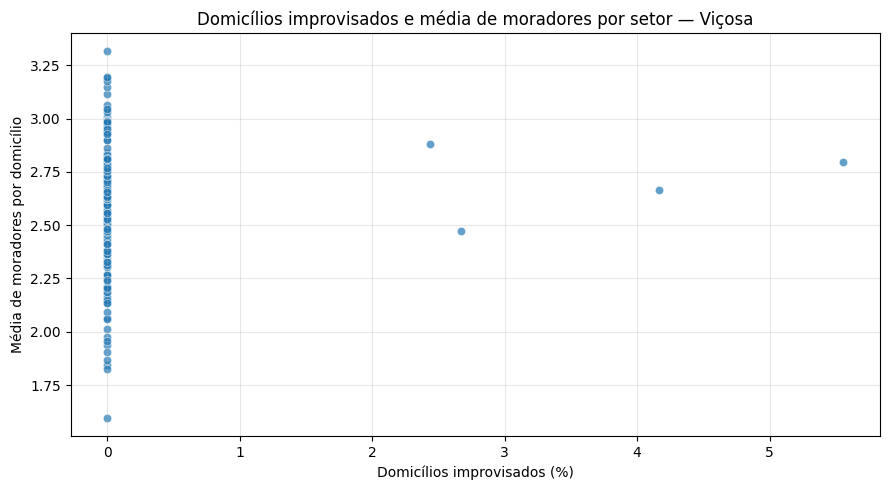

In [39]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=variaveis_correlacao,
    x="PCT_IMPROVISADOS",
    y="MEDIA_MORADORES",
    alpha=0.7
)

plt.title(
    "Domicílios improvisados e média de moradores por setor — Viçosa"
)

plt.xlabel("Domicílios improvisados (%)")
plt.ylabel("Média de moradores por domicílio")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

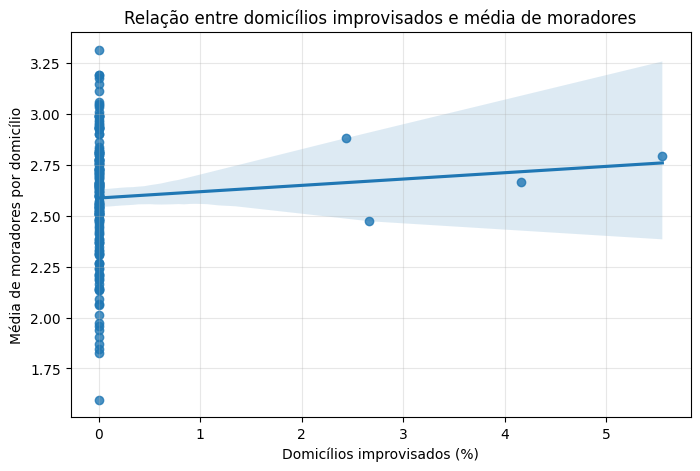

In [40]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.regplot(
    data=variaveis_correlacao,
    x="PCT_IMPROVISADOS",
    y="MEDIA_MORADORES"
)

plt.title(
    "Relação entre domicílios improvisados e média de moradores"
)

plt.xlabel("Domicílios improvisados (%)")
plt.ylabel("Média de moradores por domicílio")

plt.grid(alpha=0.3)
plt.show()


Os coeficientes de Pearson e Spearman apresentaram valores próximos de zero, indicando uma associação muito fraca entre os indicadores nos setores analisados.

Os valores-p foram superiores a 0,05, não permitindo identificar evidência estatística suficiente de associação entre as variáveis.

Entretanto, esse resultado deve ser interpretado considerando a distribuição do percentual de domicílios improvisados: apenas quatro dos 172 setores apresentam valores acima de zero. A concentração de observações em zero limita a variabilidade do indicador e influencia os resultados da análise de correlação.

Assim, os resultados não permitem concluir que essas características sejam independentes. Eles também evidenciam a necessidade de considerar a distribuição e a variabilidade das variáveis antes de aplicar e interpretar medidas de correlação.

# 6. Considerações finais: da análise territorial à desagregação espacial

Ao longo das duas atividades, exploramos informações do Censo Demográfico 2022 em diferentes escalas territoriais.

Em Minas Gerais, trabalhamos com a agregação de informações por município, construímos indicadores e investigamos associações estatísticas entre características domiciliares.

Em Viçosa, aproximamos a escala de análise e observamos diferenças entre setores censitários, demonstrando como informações em escala intraurbana podem revelar variações que não aparecem nos dados agregados por município.

Entretanto, a disponibilidade de indicadores por setor não significa que todas as dimensões das condições habitacionais estejam representadas nessa escala.

Surge, portanto, uma questão importante:

**Como estimar a distribuição territorial de informações que estão disponíveis apenas em escalas mais agregadas?**

Esse problema está relacionado à desagregação espacial, que busca estimar informações em unidades territoriais mais detalhadas, utilizando dados auxiliares e métodos estatísticos ou de aprendizado de máquina.

A aplicação dessas técnicas exige atenção à qualidade dos dados, à escolha das variáveis explicativas, à validação dos resultados e à interpretação das estimativas.

Assim, a manipulação e a análise exploratória dos dados constituem etapas fundamentais para o desenvolvimento de modelos de desagregação espacial.